# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170105          # <-- your full roll number
NAME = "Tikshan Garg"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170105   Name: Tikshan Garg   Fingerprint: BF7446FE   Tickets: 12

Ticket_ID                                                               Ticket_Text
      T01               Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T02                    The printer crashes while opening. Can you check this?
      T03 I tried restarting the MATLAB since yesterday. Is there another solution?
      T04                                               The file is 95.5% uploaded.
      T05                   The printer was working yesterday. It worked yesterday.
      T06            Projector has stopped syncing on my laptop. Please resolve it.
      T07 I was locked out of the lms after the latest update. It worked yesterday.
      T08 I reinstalled the lms after the latest update. Is there another solution?
      T09                           The lms keeps asking for login. This is urgent.
      T10                                        Dr. Rao's lab PC (No. 14) i

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Your code

results = []

for _, row in df.iterrows():

    ticket_id = row["Ticket_ID"]
    ticket_text = row["Ticket_Text"]

    # Apply the official preprocessing function
    result = process_ticket(ticket_text)

    results.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

q1_df = pd.DataFrame(results)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_df["Sentences"].sum(),
    "Tokens": q1_df["Tokens"].sum(),
    "Punctuation Tokens": q1_df["Punctuation Tokens"].sum(),
    "Stopwords": q1_df["Stopwords"].sum(),
    "Unique Tokens": q1_df["Unique Tokens"].sum(),
    "Final Tokens": q1_df["Final Tokens"].sum()
}

q1_final = pd.concat(
    [q1_df, pd.DataFrame([total_row])],
    ignore_index=True
)

display(q1_final)

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,1,9,2,2,9,5
1,T02,2,11,2,5,11,4
2,T03,2,13,2,4,13,7
3,T04,1,7,2,2,7,3
4,T05,2,10,2,3,8,5
5,T06,2,12,2,4,11,6
6,T07,2,16,2,8,14,6
7,T08,2,14,2,6,13,6
8,T09,2,11,2,4,10,5
9,T10,2,13,4,3,12,6


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

Some final tokens are not complete English words, such as `n't`, `'s`, and `ca`.

These tokens mainly come from contractions. The `word_tokenize()` function used by the official preprocessing pipeline separates contractions into smaller tokens. For example, `can't` can become `ca` and `n't`, while `isn't` can become `is` and `n't`. Similarly, possessive forms such as `student's` can produce `'s`.

These fragments remain in the final tokens because they are not necessarily classified as punctuation or stopwords by the preprocessing pipeline.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

import re

# Words longer than 5 letters
long_words_pattern = r'\b[A-Za-z]{6,}\b'

# Numbers:
# Keeps decimals such as 95.5 and versions such as 2.0.1 whole.
numbers_pattern = r'\b\d+(?:\.\d+)+\b|\b\d+\b'

# Capitalized words
capitalized_pattern = r'\b[A-Z][A-Za-z]*\b'

# Words starting with a vowel
vowel_words_pattern = r'\b[AEIOUaeiou][A-Za-z]*\b'

# Email addresses
email_pattern = r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b'

# URLs
url_pattern = r'(?:https?://|www\.)[^\s]+'

# Phone numbers
phone_pattern = r'(?<!\w)(?:\+\d{1,3}[-.\s]?)?(?:\d{3,5}[-.\s]){1,2}\d{3,5}(?!\w)'

for _, row in df.iterrows():

    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    long_words = re.findall(long_words_pattern, text)
    numbers = re.findall(numbers_pattern, text)
    capitalized_words = re.findall(capitalized_pattern, text)
    vowel_words = re.findall(vowel_words_pattern, text)

    print("=" * 80)
    print("Ticket:", ticket_id)

    print("\nWords longer than 5 letters:")
    print(long_words)

    print("\nNumbers:")
    print(numbers)

    print("\nCapitalized words:")
    print(capitalized_words)

    print("\nWords starting with a vowel:")
    print(vowel_words)

print("\n\n" + "=" * 80)
print("TEST_LINES — EXTRACTION")
print("=" * 80)

for i, line in enumerate(TEST_LINES, start=1):

    print(f"\nTEST LINE {i}:")
    print(line)

    print("\nWords longer than 5 letters:")
    print(re.findall(long_words_pattern, line))

    print("\nNumbers:")
    print(re.findall(numbers_pattern, line))

    print("\nCapitalized words:")
    print(re.findall(capitalized_pattern, line))

    print("\nWords starting with a vowel:")
    print(re.findall(vowel_words_pattern, line))

def replace_patterns(text):

    # Replace email addresses
    text = re.sub(email_pattern, "<EMAIL>", text)

    # Replace URLs
    text = re.sub(url_pattern, "<URL>", text)

    # Replace phone numbers
    text = re.sub(phone_pattern, "<PHONE>", text)

    return text

print("\n\n" + "=" * 80)
print("TEST_LINES — REPLACEMENT")
print("=" * 80)

for i, line in enumerate(TEST_LINES, start=1):

    print(f"\nTEST LINE {i}:")
    print("Original:")
    print(line)

    print("\nAfter replacement:")
    print(replace_patterns(line))

replaced_tickets = []

for _, row in df.iterrows():

    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    replaced_text = replace_patterns(text)

    replaced_tickets.append({
        "Ticket_ID": ticket_id,
        "Original": text,
        "Replaced": replaced_text
    })


q2_replaced_df = pd.DataFrame(replaced_tickets)

display(q2_replaced_df)

Ticket: T01

Words longer than 5 letters:
['helpdesk', 'thapar', 'thapar']

Numbers:
[]

Capitalized words:
['Write']

Words starting with a vowel:
['it', 'edu', 'or', 'edu', 'it']
Ticket: T02

Words longer than 5 letters:
['printer', 'crashes', 'opening']

Numbers:
[]

Capitalized words:
['The', 'Can']

Words starting with a vowel:
['opening']
Ticket: T03

Words longer than 5 letters:
['restarting', 'MATLAB', 'yesterday', 'another', 'solution']

Numbers:
[]

Capitalized words:
['I', 'MATLAB', 'Is']

Words starting with a vowel:
['I', 'Is', 'another']
Ticket: T04

Words longer than 5 letters:
['uploaded']

Numbers:
['95.5']

Capitalized words:
['The']

Words starting with a vowel:
['is', 'uploaded']
Ticket: T05

Words longer than 5 letters:
['printer', 'working', 'yesterday', 'worked', 'yesterday']

Numbers:
[]

Capitalized words:
['The', 'It']

Words starting with a vowel:
['It']
Ticket: T06

Words longer than 5 letters:
['Projector', 'stopped', 'syncing', 'laptop', 'Please', 'resolve

,Ticket_ID,Original,Replaced
0,T01,Write to it.helpdesk@thapar.edu or visit www.t...,Write to <EMAIL> or visit <URL>
1,T02,The printer crashes while opening. Can you che...,The printer crashes while opening. Can you che...
2,T03,I tried restarting the MATLAB since yesterday....,I tried restarting the MATLAB since yesterday....
3,T04,The file is 95.5% uploaded.,The file is 95.5% uploaded.
4,T05,The printer was working yesterday. It worked y...,The printer was working yesterday. It worked y...
5,T06,Projector has stopped syncing on my laptop. Pl...,Projector has stopped syncing on my laptop. Pl...
6,T07,I was locked out of the lms after the latest u...,I was locked out of the lms after the latest u...
7,T08,I reinstalled the lms after the latest update....,I reinstalled the lms after the latest update....
8,T09,The lms keeps asking for login. This is urgent.,The lms keeps asking for login. This is urgent.
9,T10,Dr. Rao's lab PC (No. 14) is down.,Dr. Rao's lab PC (No. 14) is down.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

From the generated support-ticket dataset, **12** capitalized words are capitalized only because they occur at the beginning of a sentence.

These words are not necessarily proper nouns; their capitalization is caused by their sentence position.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code

from nltk.tokenize import RegexpTokenizer

pattern = r"""https?://[^\s]+?(?=[.,!?;:]?(?:\s|$))|www\.[^\s]+?(?=[.,!?;:]?(?:\s|$))|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|(?<!\w)(?:\+\d{1,3}[-.\s]?)?(?:\d{3,5}[-.\s]){1,2}\d{3,5}(?!\w)|\d+(?:\.\d+)+|\b[A-Za-z]+(?:-[A-Za-z]+)+\b|\b[A-Za-z]+(?:'[A-Za-z]+)\b|\b[A-Za-z]+\b|[^\w\s]"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

print("TEST_LINES\n")

for i, line in enumerate(TEST_LINES, 1):
    print("TEST LINE {i}:")
    print(my_tokenize(line))
    print()

print("=" * 80)
print("TICKET COMPARISON")
print("=" * 80)

different_tickets = []

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    same = custom_tokens == nltk_tokens

    print("{ticket_id}")
    print("my_tokenize :", custom_tokens)
    print("word_tokenize:", nltk_tokens)
    print("Same:", same)

    if not same:
        different_tickets.append(ticket_id)

print("Tickets tokenized differently:", different_tickets)
print("Number of different tickets:", len(different_tickets))

TEST_LINES

TEST LINE {i}:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

TEST LINE {i}:
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', ',', '.']

TEST LINE {i}:
['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']

TICKET COMPARISON
{ticket_id}
my_tokenize : ['Write', 'to', 'it.helpdesk@thapar.edu', 'or', 'visit', 'www.thapar.edu/it', '.']
word_tokenize: ['Write', 'to', 'it.helpdesk', '@', 'thapar.edu', 'or', 'visit', 'www.thapar.edu/it', '.']
Same: False
{ticket_id}
my_tokenize : ['The', 'printer', 'crashes', 'while', 'opening', '.', 'Can', 'you', 'check', 'this', '?']
word_tokenize: ['The', 'printer', 'crashes', 'while', 'opening', '.', 'Can', 'you', 'check', 'this', '?']
Same: True
{ticket_id}
my_tokenize : ['I', 'tried'

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

**3 tickets** are tokenized differently by `my_tokenize()` and `word_tokenize()`.

The different tickets are **T01, T10, and T12**.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()
regex_stemmer = RegexpStemmer(r"(ing|ed|es|s)$", min=4)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

all_tokens = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    all_tokens.extend(result["final"])

unique_words = list(dict.fromkeys(
    token.lower() for token in all_tokens if token.isalpha()
))

pos_tags = nltk.pos_tag(unique_words)

rows = []

for word, tag in pos_tags:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regex_stemmer.stem(word)
    w = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    if len({p, l, r, w}) > 1:
        rows.append({
            "Word": word,
            "POS": tag,
            "Porter": p,
            "Lancaster": l,
            "Regexp": r,
            "WordNet": w
        })

q4_df = pd.DataFrame(rows)

display(q4_df)

,Word,POS,Porter,Lancaster,Regexp,WordNet
0,write,JJ,write,writ,write,write
1,printer,NN,printer,print,printer,printer
2,opening,VBG,open,op,open,open
3,tried,VBD,tri,tri,tri,try
4,since,IN,sinc,sint,since,since
5,another,DT,anoth,anoth,another,another
6,solution,NN,solut,solv,solution,solution
7,file,NN,file,fil,file,file
8,projector,NN,projector,project,projector,projector
9,stopped,VBD,stop,stop,stopp,stop


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

### Answer

- **Over-stemming:** `latest → latest` by Porter but `late` by WordNet; Lancaster also produces `latest`.
- **Under-stemming:** `tried → tri` by Porter/Lancaster, while WordNet correctly gives `try`.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Set,Tokens,Unique Tokens,TTR
0,S1,135,73,0.5407
1,S2,110,67,0.6091
2,S3,62,45,0.7258
3,S4,62,44,0.7097


Top 10 words of S1:
[('.', 16), ('the', 11), ('is', 7), ('?', 5), ('yesterday', 5), ('i', 3), ('there', 3), ('another', 3), ('solution', 3), ('was', 3)]

Top 10 words of S3:
[('yesterday', 5), ('another', 3), ('solution', 3), ('lms', 3), ('printer', 2), ('opening', 2), ('working', 2), ('worked', 2), ('latest', 2), ('update', 2)]


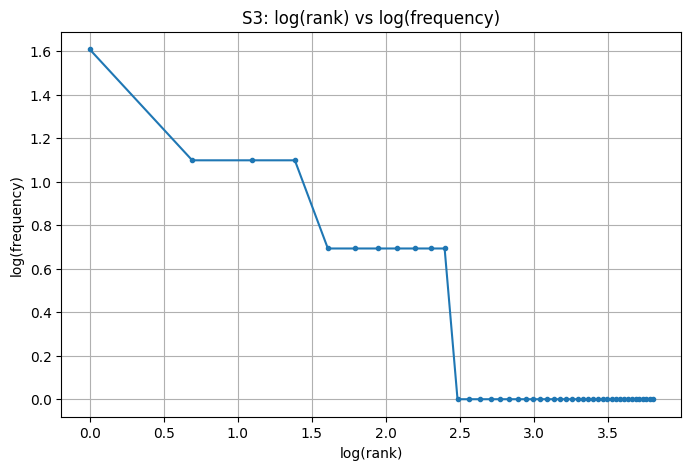

Top 5 bigrams of S1:
[(('yesterday', '.'), 5), (('.', 'the'), 3), (('.', 'is'), 3), (('is', 'there'), 3), (('there', 'another'), 3)]

Top 5 bigrams of S3:
[(('another', 'solution'), 3), (('yesterday', 'another'), 2), (('working', 'yesterday'), 2), (('worked', 'yesterday'), 2), (('lms', 'latest'), 2)]


In [ ]:
# Your code

import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams

porter = PorterStemmer()

S1 = []
S2 = []
S3 = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    S1.extend(result["tokens"])
    S2.extend([t for t in result["tokens"] if t not in string.punctuation])
    S3.extend(result["final"])

S4 = [porter.stem(t) for t in S3]

def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0
    return total, unique, ttr

stats = []

for name, tokens in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    total, unique, ttr = corpus_stats(tokens)
    stats.append({
        "Set": name,
        "Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)
display(stats_df)

print("Top 10 words of S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words of S3:")
print(Counter(S3).most_common(10))

freq = Counter(S3)
rank_freq = sorted(freq.values(), reverse=True)

ranks = np.arange(1, len(rank_freq) + 1)

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(rank_freq), marker="o", markersize=3)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3: log(rank) vs log(frequency)")
plt.grid(True)
plt.show()

print("Top 5 bigrams of S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams of S3:")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

TTR increases from **0.5407 (S1)** to **0.6091 (S2)** and then to **0.7258 (S3)** because preprocessing removes punctuation and stopwords, reducing the total number of tokens more than the number of unique tokens.

From **S3 to S4**, TTR slightly decreases from **0.7258 to 0.7097**. Porter stemming reduces the number of unique tokens from **45 to 44** while the total number of tokens remains **62**.

## Q6. Interpretation

Answer briefly:

**(a)** Why does TTR change from S1 to S4 in your dataset?

**(b)** Give one example where `word_tokenize()` and your tokenizer differ. Explain the difference.

**(c)** Give one example where stemming produces an undesirable result.

**(d)** Give one example where POS-aware lemmatization preserves meaning better than stemming.

**(a)** TTR increases from S1 to S3 because preprocessing removes punctuation and stopwords, reducing the total number of tokens more than the number of unique tokens. From S3 to S4, stemming reduces unique tokens from 45 to 44, so TTR slightly decreases.

**(b)** For example, `isn't` is kept as one token by `my_tokenize()`, while `word_tokenize()` splits it into `is` and `n't`. The custom tokenizer is designed to preserve contractions as single tokens.

**(c)** An undesirable stemming result is `tried → tri` with PorterStemmer. The resulting stem is not a meaningful English word.

**(d)** For example, `tried → try` with WordNetLemmatizer, while stemming gives `tri`. POS-aware lemmatization therefore preserves the intended meaning better.